In [1]:
!pip install xgboost scikit-learn seaborn --quiet

Dataset Loaded Successfully!
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000

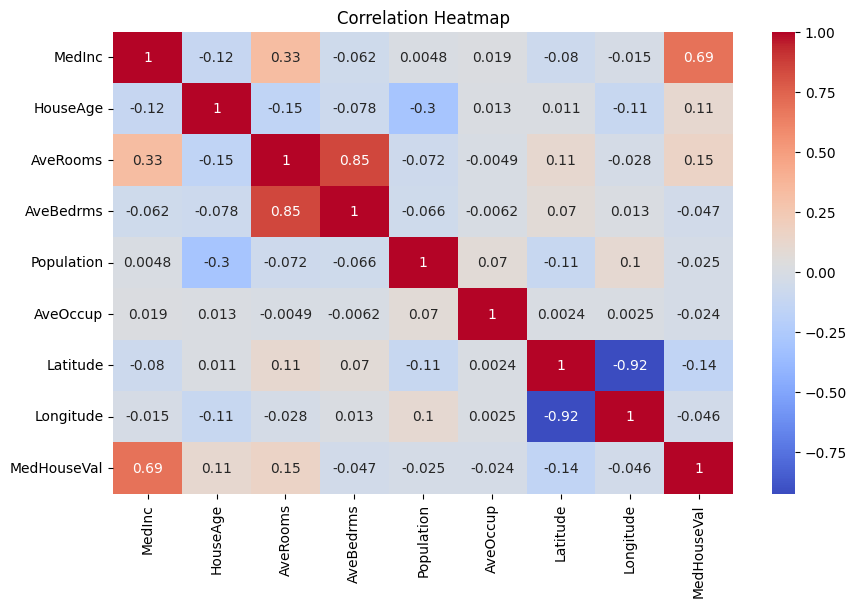

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Load Dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("Dataset Loaded Successfully!")
print(df.head())
print(df.describe())

# Check for null values
print(df.isnull().sum())

# Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [8]:
# Split Features and Target
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale data for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

for name, model in models.items():
    if name == "Linear Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"--- {name} ---")
    print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | R2 Score: {r2:.3f}\n")

--- Linear Regression ---
MAE: 0.533 | RMSE: 0.746 | R2 Score: 0.576

--- Random Forest ---
MAE: 0.328 | RMSE: 0.505 | R2 Score: 0.805

--- XGBoost ---
MAE: 0.316 | RMSE: 0.474 | R2 Score: 0.829



In [9]:
# Save Best Model
best_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
best_model.fit(X_train, y_train)
joblib.dump(best_model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model Saved as model.pkl and scaler.pkl")

# Test with a new house
# Features: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude
new_house = np.array([[8.0, 20, 6, 1.2, 3000, 3, 34.0, -118.2]])
predicted_price = best_model.predict(new_house)
print(f"Predicted House Price for new house: ${predicted_price[0]*100000:,.2f}")

Model Saved as model.pkl and scaler.pkl
Predicted House Price for new house: $467,418.28
